In [100]:
import io
import os

In [101]:
import gzip
import pickle #for serializing and de-serializing a Python object structure into text
import numpy as np
import pandas as pd
import urllib.request

In [102]:
import matplotlib.pyplot as plt
%matplotlib inline

In [103]:
import boto3
import sagemaker #train & deploy models in AWS
import sagemaker.amazon.common as smac #utility to get data in the right format for training
from sagemaker import get_execution_role #access ARN whose credential are used to access ML APIs
from sagemaker.predictor import csv_serializer, json_deserializer #serialize data to our prediction API

In [104]:
DOWNLOADED_FILENAME = 'mnist.pkl.gz'

In [105]:
if not os.path.exists(DOWNLOADED_FILENAME):
    urllib.request.urlretrieve('http://deeplearning.net/data/mnist/mnist.pkl.gz', DOWNLOADED_FILENAME)

In [106]:
with gzip.open('mnist.pkl.gz', 'rb') as f:
    train_set, valid_set, test_set = pickle.load(f, encoding='latin1')

In [107]:
type(train_set)

tuple

In [108]:
print(len(train_set))

2


In [109]:
train_set[0].shape #5.000 images, each image is 28x28=784 pixels

(50000, 784)

In [110]:
train_set[1][30]

3

In [111]:
print(train_set[0].shape)
print(valid_set[0].shape)
print(test_set[0].shape)

(50000, 784)
(10000, 784)
(10000, 784)


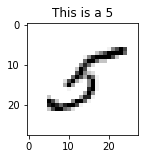

In [133]:
def show_digit(img, caption=''):
    plt.rcParams['figure.figsize'] = (2,10)
    plt.imshow(img.reshape(28,28), cmap='Greys', interpolation='nearest')
    plt.title(caption)
    
show_digit(train_set[0][35], 'This is a {}'.format(train_set[1][35]))

In [113]:
#Prepare the data to fit in the linear model
vectors = np.array(train_set[0]).astype('float32')
vectors.shape

(50000, 784)

In [114]:
labels = np.where(train_set[1] == 3,1,0).astype('float32')
labels.shape

(50000,)

In [115]:
labels[:20]

array([0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 1., 0., 1., 0., 0., 0., 0.,
       0., 0., 0.], dtype=float32)

END OF DATA PREPARATION
------
BEGIN of training

In [116]:
buf = io.BytesIO() #the model expected being serialized in a byte form
smac.write_numpy_to_dense_tensor(buf, vectors, labels)



In [117]:
buf.seek(0) #seek the begining of the buffer

0

In [118]:
bucket = 'alexbc-sagemaker-us' #bucket to upload training data
prefix = 'sagemaker/linear-mnist'
key = 'recordio-pb-data'

In [119]:
resource = boto3.resource('s3')
bucket_obj=resource.Bucket(bucket)
object_res=bucket_obj.Object(os.path.join(prefix, 'train', key)) #reference to the object which hold the data

train_data_loc = 's3://{}/{}/train/{}'.format(bucket, prefix, key)
print('uploaded training data location{}'.format(train_data_loc))

uploaded training data locations3://alexbc-sagemaker-us/sagemaker/linear-mnist/train/recordio-pb-data


In [120]:
object_res.upload_fileobj(buf)

In [121]:
#output of training model dataset
output_location = 's3://{}/{}/output'.format(bucket, prefix)
print('Training artifacts will be uploaded to: {}'.format(output_location))


Training artifacts will be uploaded to: s3://alexbc-sagemaker-us/sagemaker/linear-mnist/output


In [122]:
region = boto3.Session().region_name
region

'us-east-1'

In [123]:
#built-in algorithms are available in containers across different AWS regions
containers = {'us-west-2': '174872318107.dkr.ecr.us-west-2.amazonaws.com/linear-learner:latest',
              'us-east-1': '382416733822.dkr.ecr.us-east-1.amazonaws.com/linear-learner:latest',
              'us-east-2': '404615174143.dkr.ecr.us-east-2.amazonaws.com/linear-learner:latest',
              'eu-west-1': '438346466558.dkr.ecr.eu-west-1.amazonaws.com/linear-learner:latest'}
container = containers[region]

In [124]:
sess = sagemaker.Session()

In [125]:
role = get_execution_role()
role

'arn:aws:iam::771620814942:role/service-role/AmazonSageMaker-ExecutionRole-20171212T090635'

In [126]:
#Same estimator of tensorflow. Abstracts bias, training, prediction process
linear = sagemaker.estimator.Estimator(container,
                                       role,
                                       train_instance_count=1,
                                       train_instance_type='ml.m5.4xlarge',
                                       output_path=output_location,
                                       sagemaker_session=sess)

In [127]:
linear.set_hyperparameters(feature_dim=784,
                           predictor_type='binary_classifier',
                           mini_batch_size=200)


In [128]:
linear.fit({'train': train_data_loc})

INFO:sagemaker:Creating training-job with name: linear-learner-2018-04-28-15-55-58-121


........................................
Docker entrypoint called with argument(s): train
[04/28/2018 15:59:06 INFO 139890245314368] Reading default configuration from /opt/amazon/lib/python2.7/site-packages/algorithm/default-input.json: {u'loss_insensitivity': u'0.01', u'epochs': u'10', u'init_bias': u'0.0', u'lr_scheduler_factor': u'0.99', u'num_calibration_samples': u'10000000', u'_num_kv_servers': u'auto', u'use_bias': u'true', u'num_point_for_scaler': u'10000', u'_log_level': u'info', u'quantile': u'0.5', u'bias_lr_mult': u'10', u'lr_scheduler_step': u'100', u'init_method': u'uniform', u'init_sigma': u'0.01', u'lr_scheduler_minimum_lr': u'0.00001', u'target_recall': u'0.8', u'num_models': u'32', u'early_stopping_patience': u'3', u'momentum': u'0.0', u'unbias_label': u'auto', u'wd': u'0.0', u'optimizer': u'adam', u'_tuning_objective_metric': u'', u'early_stopping_tolerance': u'0.001', u'learning_rate': u'auto', u'_kvstore': u'auto', u'normalize_data': u'true', u'binary_classifier_m

#metrics {"Metrics": {"training_binary_classification_cross_entropy": {"count": 1, "max": 0.09646111852645874, "sum": 0.09646111852645874, "min": 0.09646111852645874}}, "EndTime": 1524931155.222439, "Dimensions": {"model": 0, "Host": "algo-1", "Operation": "training", "Algorithm": "Linear Learner", "epoch": 1}, "StartTime": 1524931155.222358}

#metrics {"Metrics": {"training_binary_classification_cross_entropy": {"count": 1, "max": 0.0956951375579834, "sum": 0.0956951375579834, "min": 0.0956951375579834}}, "EndTime": 1524931155.222523, "Dimensions": {"model": 1, "Host": "algo-1", "Operation": "training", "Algorithm": "Linear Learner", "epoch": 1}, "StartTime": 1524931155.222512}

#metrics {"Metrics": {"training_binary_classification_cross_entropy": {"count": 1, "max": 0.09657997985839843, "sum": 0.09657997985839843, "min": 0.09657997985839843}}, "EndTime": 1524931155.222556, "Dimensions": {"model": 2, "Host": "algo-1", "Operation": "training", "Algorithm": "Linear Learner", "epoch": 1}

#metrics {"Metrics": {"training_binary_classification_cross_entropy": {"count": 1, "max": 0.08615342847824096, "sum": 0.08615342847824096, "min": 0.08615342847824096}}, "EndTime": 1524931163.623504, "Dimensions": {"model": 0, "Host": "algo-1", "Operation": "training", "Algorithm": "Linear Learner", "epoch": 3}, "StartTime": 1524931163.623442}

#metrics {"Metrics": {"training_binary_classification_cross_entropy": {"count": 1, "max": 0.08778175678253174, "sum": 0.08778175678253174, "min": 0.08778175678253174}}, "EndTime": 1524931163.623574, "Dimensions": {"model": 1, "Host": "algo-1", "Operation": "training", "Algorithm": "Linear Learner", "epoch": 3}, "StartTime": 1524931163.623565}

#metrics {"Metrics": {"training_binary_classification_cross_entropy": {"count": 1, "max": 0.0859182664680481, "sum": 0.0859182664680481, "min": 0.0859182664680481}}, "EndTime": 1524931163.623602, "Dimensions": {"model": 2, "Host": "algo-1", "Operation": "training", "Algorithm": "Linear Learner", "epoch": 3}

#metrics {"Metrics": {"training_binary_classification_cross_entropy": {"count": 1, "max": 0.08408354800224305, "sum": 0.08408354800224305, "min": 0.08408354800224305}}, "EndTime": 1524931167.788676, "Dimensions": {"model": 0, "Host": "algo-1", "Operation": "training", "Algorithm": "Linear Learner", "epoch": 4}, "StartTime": 1524931167.788619}

#metrics {"Metrics": {"training_binary_classification_cross_entropy": {"count": 1, "max": 0.08657575407981873, "sum": 0.08657575407981873, "min": 0.08657575407981873}}, "EndTime": 1524931167.788745, "Dimensions": {"model": 1, "Host": "algo-1", "Operation": "training", "Algorithm": "Linear Learner", "epoch": 4}, "StartTime": 1524931167.788736}

#metrics {"Metrics": {"training_binary_classification_cross_entropy": {"count": 1, "max": 0.08365524976730347, "sum": 0.08365524976730347, "min": 0.08365524976730347}}, "EndTime": 1524931167.788772, "Dimensions": {"model": 2, "Host": "algo-1", "Operation": "training", "Algorithm": "Linear Learner", "epoch":

#metrics {"Metrics": {"training_binary_classification_cross_entropy": {"count": 1, "max": 0.0815094160938263, "sum": 0.0815094160938263, "min": 0.0815094160938263}}, "EndTime": 1524931176.156251, "Dimensions": {"model": 0, "Host": "algo-1", "Operation": "training", "Algorithm": "Linear Learner", "epoch": 6}, "StartTime": 1524931176.156191}

#metrics {"Metrics": {"training_binary_classification_cross_entropy": {"count": 1, "max": 0.08567238166809082, "sum": 0.08567238166809082, "min": 0.08567238166809082}}, "EndTime": 1524931176.156321, "Dimensions": {"model": 1, "Host": "algo-1", "Operation": "training", "Algorithm": "Linear Learner", "epoch": 6}, "StartTime": 1524931176.156312}

#metrics {"Metrics": {"training_binary_classification_cross_entropy": {"count": 1, "max": 0.08132421226501464, "sum": 0.08132421226501464, "min": 0.08132421226501464}}, "EndTime": 1524931176.156348, "Dimensions": {"model": 2, "Host": "algo-1", "Operation": "training", "Algorithm": "Linear Learner", "epoch": 6}

#metrics {"Metrics": {"training_binary_classification_cross_entropy": {"count": 1, "max": 0.08008822416305542, "sum": 0.08008822416305542, "min": 0.08008822416305542}}, "EndTime": 1524931184.464732, "Dimensions": {"model": 0, "Host": "algo-1", "Operation": "training", "Algorithm": "Linear Learner", "epoch": 8}, "StartTime": 1524931184.464671}

#metrics {"Metrics": {"training_binary_classification_cross_entropy": {"count": 1, "max": 0.08507766469478607, "sum": 0.08507766469478607, "min": 0.08507766469478607}}, "EndTime": 1524931184.464802, "Dimensions": {"model": 1, "Host": "algo-1", "Operation": "training", "Algorithm": "Linear Learner", "epoch": 8}, "StartTime": 1524931184.464794}

#metrics {"Metrics": {"training_binary_classification_cross_entropy": {"count": 1, "max": 0.0800120223903656, "sum": 0.0800120223903656, "min": 0.0800120223903656}}, "EndTime": 1524931184.46483, "Dimensions": {"model": 2, "Host": "algo-1", "Operation": "training", "Algorithm": "Linear Learner", "epoch": 8},

#metrics {"Metrics": {"f1": {"count": 1, "max": 0.8770352612126661, "sum": 0.8770352612126661, "min": 0.8770352612126661}, "threshold_for_accuracy": {"count": 1, "max": 0.5168483853340149, "sum": 0.5168483853340149, "min": 0.5168483853340149}, "threshold_for_precision_at_target_recall": {"count": 1, "max": 0.5939809679985046, "sum": 0.5939809679985046, "min": 0.5939809679985046}, "threshold_for_recall_at_target_precision": {"count": 1, "max": 0.24189062416553497, "sum": 0.24189062416553497, "min": 0.24189062416553497}, "recall_at_precision": {"count": 1, "max": 0.9029602038815937, "sum": 0.9029602038815937, "min": 0.9029602038815937}, "precision_at_target_recall": {"count": 1, "max": 0.939899451553932, "sum": 0.939899451553932, "min": 0.939899451553932}, "accuracy": {"count": 1, "max": 0.9758, "sum": 0.9758, "min": 0.9758}, "threshold_for_f1": {"count": 1, "max": 0.4255923330783844, "sum": 0.4255923330783844, "min": 0.4255923330783844}}, "EndTime": 1524931189.143572, "Dimensions": {"mo

--
TRaining completed. It's time for deployment

In [130]:
linear_predictor = linear.deploy(initial_instance_count=1,
                                 instance_type='ml.m5.large')

INFO:sagemaker:Creating model with name: linear-learner-2018-04-28-16-06-32-699
INFO:sagemaker:Creating endpoint with name linear-learner-2018-04-28-15-55-58-121


-------------------------------------------------------------!

In [131]:
linear_predictor.content_type='text/csv'
linear_predictor.serializer = csv_serializer
linear_predictor.deserializer = json_deserializer

In [136]:
result = linear_predictor.predict(train_set[0][30])
print(result)

{'predictions': [{'score': 0.008355999365448952, 'predicted_label': 0.0}]}


In [137]:
batched_test_set = np.array_split(test_set[0], 100)

In [140]:
print(len(test_set[0]))
print(len(batched_test_set))

10000
100


In [141]:
batched_test_set[0].shape

(100, 784)

In [142]:
predictions = []
for array in batched_test_set:
    result = linear_predictor.predict(array)
    predictions += [r['predicted_label'] for r in result['predictions']]


In [143]:
result

{'predictions': [{'predicted_label': 0.0, 'score': 0.013760939240455627},
  {'predicted_label': 0.0, 'score': 0.0005800226354040205},
  {'predicted_label': 0.0, 'score': 1.66698191605974e-05},
  {'predicted_label': 0.0, 'score': 0.005062202922999859},
  {'predicted_label': 0.0, 'score': 0.00044279679423198104},
  {'predicted_label': 0.0, 'score': 0.0007877511670812964},
  {'predicted_label': 0.0, 'score': 2.1889121853746474e-05},
  {'predicted_label': 0.0, 'score': 0.00044162891572341323},
  {'predicted_label': 0.0, 'score': 5.718477950722445e-06},
  {'predicted_label': 0.0, 'score': 7.135557098081335e-05},
  {'predicted_label': 0.0, 'score': 0.005323878955096006},
  {'predicted_label': 0.0, 'score': 3.50565678672865e-05},
  {'predicted_label': 0.0, 'score': 0.01631418988108635},
  {'predicted_label': 0.0, 'score': 9.619886986911297e-05},
  {'predicted_label': 1.0, 'score': 0.8712611794471741},
  {'predicted_label': 0.0, 'score': 3.12837291858159e-05},
  {'predicted_label': 0.0, 'score

In [145]:
predictions[:50]

[0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 1.0,
 0.0,
 1.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 1.0,
 0.0,
 1.0,
 0.0,
 0.0,
 0.0]

In [146]:
predictions = np.array(predictions)

In [147]:
# ## Creating the confusion matrix
# * Use the pandas crosstab method to compute a frequency table of two factors
actual = np.where(test_set[1] == 3, 1, 0)

In [148]:
pd.crosstab(actual, predictions, rownames=['actuals'], colnames=['predictions'])

predictions,0.0,1.0
actuals,,
0,8913,77
1,151,859


In [149]:
sess.delete_endpoint(linear_predictor.endpoint)

INFO:sagemaker:Deleting endpoint with name: linear-learner-2018-04-28-15-55-58-121
